# 365 Coffee Cafe Project

In [2]:

#Import Liabraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

file_path = 'Data/365 Coffee Cafe Dataset.xlsx' 

df = pd.read_excel(file_path, sheet_name='Dataset')
data_dictionary = pd.read_excel(file_path, sheet_name='Data Dictionary')

print("=== SUPPLIED DATA DICTIONARY ===")
display(data_dictionary)

print("=== RAW DATA OVERVIEW ===")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
print(f"Date range: {pd.to_datetime(df['transaction_date']).min().date()} to "
      f"{pd.to_datetime(df['transaction_date']).max().date()}")
print("\n=== COLUMN INFORMATION ===")
df.info()
display(df.head())

=== SUPPLIED DATA DICTIONARY ===


,Column,Type,Description,Status
0,transaction_id,Numeric,Original sale line reference,Original
1,basket_id,Text,One customer visit. Lines sharing a basket_id were bought together.,NEW
2,transaction_date,Date,"Date of sale, 1 Jan 2025 to 30 Jun 2025",Original
3,transaction_time,Time,Clock time of sale,Original
4,transaction_hour,Numeric,Hour component of the sale,Original
5,hour_of_day,Numeric,"Trading hour, 6 to 20",Original
6,weekday,Categorical,Day name,Original
7,store_id,Numeric,Branch code,Original
8,store_location,Categorical,"Branch name: P.E.C.H.S., Tipu Sultan, Khayaban e Seher",Original
9,customer_id,Text,"Repeat-customer identifier, 23,350 unique customers",NEW


=== RAW DATA OVERVIEW ===
Rows: 149,112
Columns: 31
Date range: 2025-01-01 to 2025-06-30

=== COLUMN INFORMATION ===
<class 'pandas.DataFrame'>
RangeIndex: 149112 entries, 0 to 149111
Data columns (total 31 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   transaction_id             149112 non-null  int64         
 1   basket_id                  149112 non-null  str           
 2   transaction_date           149112 non-null  datetime64[us]
 3   transaction_time           149112 non-null  str           
 4   transaction_hour           149112 non-null  int64         
 5   hour_of_day                149112 non-null  int64         
 6   weekday                    149112 non-null  str           
 7   store_id                   149112 non-null  int64         
 8   store_location             149112 non-null  str           
 9   customer_id                149112 non-null  str           
 10  customer_a

,transaction_id,basket_id,transaction_date,transaction_time,transaction_hour,hour_of_day,weekday,store_id,store_location,customer_id,customer_age,customer_gender,loyalty_tier,visit_number,days_since_previous_visit,order_channel,payment_method,product_id,product_category,product_type,product_detail,transaction_qty,unit_price,revenue,promo_code,discount_pct,discount_amount,net_revenue,wait_time_min,service_rating,returned_within_14_days
0,5,B000000,2025-01-01,07:22:41,7,7,Wednesday,5,P.E.C.H.S,C07952,35,Female,Basic,1,-1,Cafe App,Raast,57,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg,2,3.10,6.20,NONE,0,0.0,6.20,3.9,4,No
1,6,B000000,2025-01-01,07:22:41,7,7,Wednesday,5,P.E.C.H.S,C07952,35,Female,Basic,1,-1,Cafe App,Raast,77,Bakery,Scone,Oatmeal Scone,1,3.00,3.00,NONE,0,0.0,3.00,3.9,4,No
2,7,B000001,2025-01-01,07:25:49,7,7,Wednesday,5,P.E.C.H.S,C04715,57,Female,Platinum,1,-1,Cafe App,Easypaisa,22,Coffee,Drip coffee,Our Old Time Diner Blend Sm,1,2.00,2.00,BUNDLE15,15,0.3,1.70,4.4,5,Yes
3,8,B000002,2025-01-01,07:33:34,7,7,Wednesday,5,P.E.C.H.S,C38262,40,Male,Platinum,1,-1,Careem Quik,Easypaisa,28,Coffee,Gourmet brewed coffee,Columbian Medium Roast Sm,2,2.00,4.00,NONE,0,0.0,4.00,7.2,4,Yes
4,9,B000003,2025-01-01,07:39:13,7,7,Wednesday,5,P.E.C.H.S,C11128,72,Female,Platinum,1,-1,Cafe App,Easypaisa,39,Coffee,Barista Espresso,Latte Rg,1,4.25,4.25,NONE,0,0.0,4.25,1.6,5,Yes


### Initial Data Check & The "Grain" Problem

A quick look at the raw data gives us a few important takeaways:

* **The Basics:** We have 149,112 rows and 31 columns covering exactly 6 months of sales (Jan - Jun 2025).
* **No Missing Data:** The `.info()` output shows 149,112 non-nulls across the board, which saves us a lot of cleanup time.
* **The Grain Issue (Important):** Looking at the first few rows, it's clear that **one row = one item sold**, not one visit. For example, the first two rows share the same `basket_id` (`B000000`), meaning the customer bought a tea and a scone in the same order.

Since our target (`returned_within_14_days`) is based on a customer's *visit*, we can't feed this raw table straight into a model. We have to group the data by `basket_id` first so that one row equals one visit.

## Section 1: Initial Data Audit & Quality Checks

In this section, we inspect the raw transaction-level dataset. We verify total row/column counts, examine variable data types, check for missing values, and audit duplicate records before performing any data aggregation or transformations.

In [3]:
# 1. Missing values and data-quality checks
missing_summary = pd.DataFrame({
    'Missing Values': df.isna().sum(),
    'Missing Percentage (%)': (df.isna().sum() / len(df) * 100).round(2)
})
print("=== MISSING VALUES AUDIT ===")
display(missing_summary[missing_summary['Missing Values'] > 0]
        if df.isna().sum().sum() else missing_summary)

print(f"Total missing cells: {int(df.isna().sum().sum()):,}")
print(f"Exact duplicate rows: {int(df.duplicated().sum()):,}")

# A value of -1 means there is no previous visit in the supplied data.
# Keep this fact as a separate flag and set the numeric gap to zero.
df['is_first_visit'] = (df['days_since_previous_visit'] == -1).astype(int)
df['days_since_previous_visit_clean'] = df['days_since_previous_visit'].where(
    df['days_since_previous_visit'] >= 0, 0
)

numerical_vars = [
    'customer_age', 'visit_number', 'days_since_previous_visit_clean',
    'transaction_qty', 'unit_price', 'revenue', 'discount_pct',
    'discount_amount', 'net_revenue', 'wait_time_min', 'service_rating'
]
categorical_vars = [
    'weekday', 'store_location', 'customer_gender', 'loyalty_tier',
    'order_channel', 'payment_method', 'product_category', 'product_type',
    'product_detail', 'promo_code'
]
identifier_vars = ['transaction_id', 'basket_id', 'store_id', 'customer_id', 'product_id']
time_vars = ['transaction_date', 'transaction_time', 'transaction_hour', 'hour_of_day']
target_var = 'returned_within_14_days'

print("\\n=== VARIABLE GROUPS (confirm against the supplied Data Dictionary) ===")
print(f"Numerical ({len(numerical_vars)}): {numerical_vars}")
print(f"Categorical ({len(categorical_vars)}): {categorical_vars}")
print(f"Identifiers ({len(identifier_vars)}): {identifier_vars}")
print(f"Date/time ({len(time_vars)}): {time_vars}")
print(f"Target (separate from predictors): {target_var}")


=== MISSING VALUES AUDIT ===


,Missing Values,Missing Percentage (%)
transaction_id,0,0.0
basket_id,0,0.0
transaction_date,0,0.0
transaction_time,0,0.0
transaction_hour,0,0.0
hour_of_day,0,0.0
weekday,0,0.0
store_id,0,0.0
store_location,0,0.0
customer_id,0,0.0


Total missing cells: 0
Exact duplicate rows: 0
\n=== VARIABLE GROUPS (confirm against the supplied Data Dictionary) ===
Numerical (11): ['customer_age', 'visit_number', 'days_since_previous_visit_clean', 'transaction_qty', 'unit_price', 'revenue', 'discount_pct', 'discount_amount', 'net_revenue', 'wait_time_min', 'service_rating']
Categorical (10): ['weekday', 'store_location', 'customer_gender', 'loyalty_tier', 'order_channel', 'payment_method', 'product_category', 'product_type', 'product_detail', 'promo_code']
Identifiers (5): ['transaction_id', 'basket_id', 'store_id', 'customer_id', 'product_id']
Date/time (4): ['transaction_date', 'transaction_time', 'transaction_hour', 'hour_of_day']
Target (separate from predictors): returned_within_14_days



###  Formal Data Audit & Variable Categorization

Even though our initial `.info()` check looked clean, I ran a strict audit here to fulfill the requirements and properly set up our variables.

* **Zero Missing or Duplicate Data:** The formal checks confirm we have exactly 0 missing cells and 0 duplicate rows across the entire dataset. This is a huge time-saver, meaning we can skip complex data imputation and trust the records as they are.


* **Organizing the Features:** Following the provided Data Dictionary, I've explicitly split all 31 columns into logical buckets: Numerical (11), Categorical (10), Identifiers (5), and Date/time (4). Our main target variable (`returned_within_14_days`) is also properly isolated from the predictors.


* **Why this setup matters:** Grouping these columns right now makes the data preparation stage much clearer. It tells us exactly which numerical columns can be calculated, which categorical variables will need encoding, and which unique identifiers (like `transaction_id`) we must deliberately drop later so our model doesn't memorize the data.

## Section 2: Exploratory Data Analysis (EDA) & Business Insights

Before we reshape this data into a visit-level table for our model, let's explore these 149,112 item-level transactions to understand how the business is currently performing.

I am visualizing the core business metrics here like revenue by branch, peak hours, popular product categories, and our baseline 14-day return rate.

An unlabelled chart is just decoration. As required, every single visualization below includes a direct takeaway explaining exactly what the results mean for café management and daily operations.

### 1. Net Revenue by Store Branch

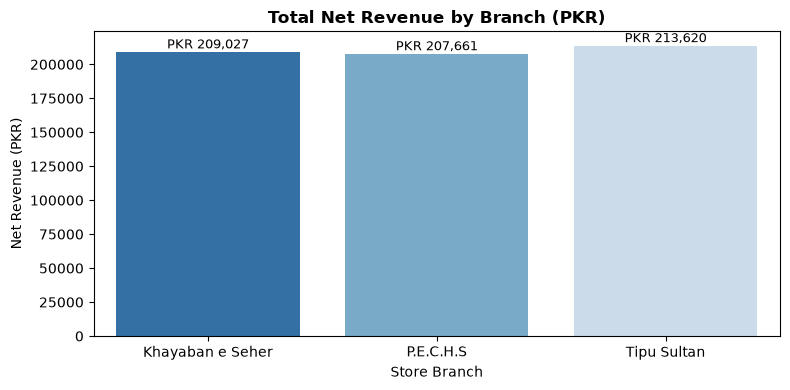

In [4]:
# 1. Total Net Revenue by Store Branch
plt.figure(figsize=(8, 4))
branch_rev = df.groupby('store_location')['net_revenue'].sum().reset_index()

ax1 = sns.barplot(
    data=branch_rev, 
    x='store_location', 
    y='net_revenue', 
    hue='store_location', 
    palette='Blues_r', 
    legend=False
)

plt.title('Total Net Revenue by Branch (PKR)', fontsize=12, fontweight='bold')
plt.xlabel('Store Branch', fontsize=10)
plt.ylabel('Net Revenue (PKR)', fontsize=10)

for p in ax1.patches:
    ax1.annotate(f'PKR {p.get_height():,.0f}', 
                 (p.get_x() + p.get_width() / 2., p.get_height()), 
                 ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=9)

plt.tight_layout()
plt.show()


### Total Net Revenue by Branch Insights

**Business Interpretation:** All three branches show remarkably consistent top-line performance, with Tipu Sultan (PKR 213,620) only slightly ahead of P.E.C.H.S (PKR 207,661). However, we must be careful with our conclusions here; revenue alone doesn't tell the whole story. Since this dataset lacks operational context like staff rosters, operating costs, or profit margins, management should use this consistent revenue baseline to roll out uniform loyalty programs system-wide, rather than making isolated staffing or investment decisions based solely on these numbers.

### 2. Net Revenue by Product Category

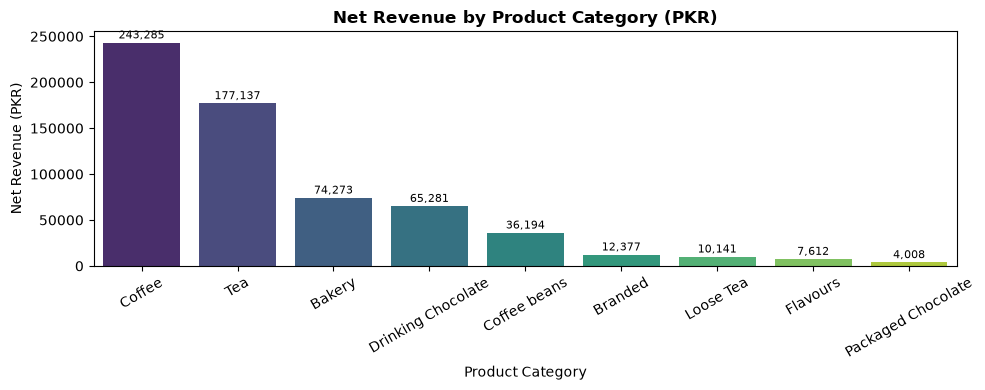

In [5]:
# 2. Net Revenue by Product Category
plt.figure(figsize=(10, 4))
cat_rev = df.groupby('product_category')['net_revenue'].sum().sort_values(ascending=False).reset_index()

ax2 = sns.barplot(
    data=cat_rev, 
    x='product_category', 
    y='net_revenue', 
    hue='product_category', 
    palette='viridis', 
    legend=False
)

plt.title('Net Revenue by Product Category (PKR)', fontsize=12, fontweight='bold')
plt.xlabel('Product Category', fontsize=10)
plt.ylabel('Net Revenue (PKR)', fontsize=10)
plt.xticks(rotation=30)

for p in ax2.patches:
    ax2.annotate(f'{p.get_height():,.0f}', 
                 (p.get_x() + p.get_width() / 2., p.get_height()), 
                 ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=8)

plt.tight_layout()
plt.show()

### Net Revenue by Product Category Insights

**Business Interpretation:**
Looking at the numbers, Coffee (PKR 243,285) and Tea (PKR 177,137) are clearly driving the bulk of our sales. Management can use this insight to design smart promotions, like bundling our top-selling drinks with Bakery items (PKR 74,273) to encourage customers to spend a little extra per visit.

But there is an important limitation to keep in mind here: high revenue does not automatically mean high profit. Because our dataset doesn't include product costs or profit margins, we can't guarantee that these specific bundles will actually be profitable. Any new discount or bundle offer should be tested on a small scale first before a full rollout.

### 3. Hourly Sales Trend

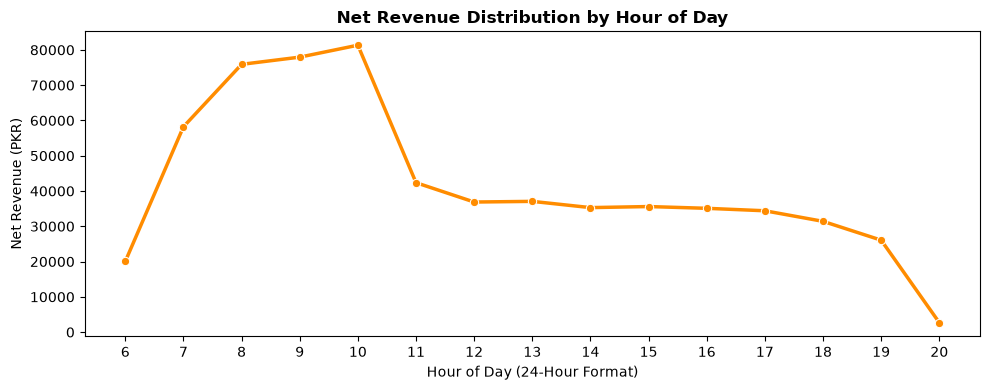

In [6]:
# 3. Peak Sales Volume by Hour of Day
plt.figure(figsize=(10, 4))
hourly_sales = df.groupby('hour_of_day')['net_revenue'].sum().reset_index()

sns.lineplot(data=hourly_sales, x='hour_of_day', y='net_revenue', marker='o', color='darkorange', linewidth=2.5)

plt.title('Net Revenue Distribution by Hour of Day', fontsize=12, fontweight='bold')
plt.xlabel('Hour of Day (24-Hour Format)', fontsize=10)
plt.ylabel('Net Revenue (PKR)', fontsize=10)
plt.xticks(range(int(df['hour_of_day'].min()), int(df['hour_of_day'].max()) + 1))
plt.tight_layout()
plt.show()

### Net Revenue Distribution by Hour of Day Insights

**Business Interpretation:**
The hourly trend clearly highlights our peak demand periods. Sales surge early in the morning, hitting their absolute highest levels between 8:00 AM and 10:00 AM (peaking just above PKR 80,000) before dropping off to a much lower, flat rate for the rest of the afternoon.

Management can use this morning peak to investigate our staffing schedules and ensure we have enough people on the floor during the rush. However, we must be careful not to jump to conclusions: this chart only measures sales volume, not customer waiting times. While it highlights our busiest hours, high revenue alone doesn't automatically prove there is a staffing bottleneck or long queues. Management should pair these sales numbers with on-the-ground observations before making any drastic changes to employee shifts.

### 4. Sales by Weekday

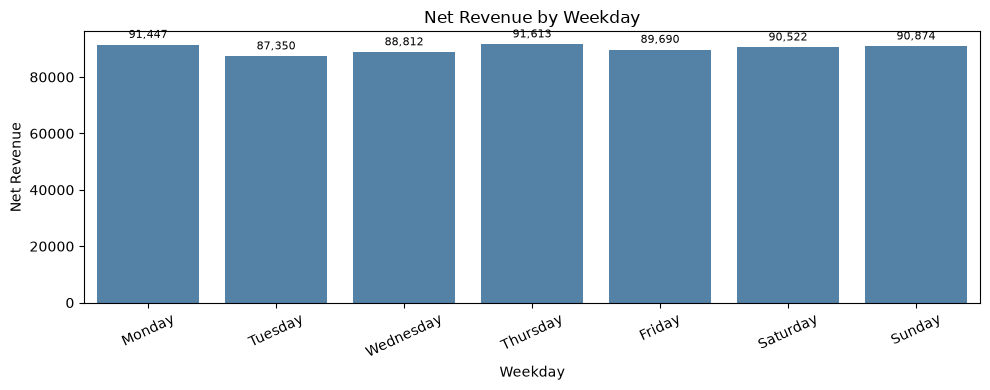

In [7]:
# Revenue by weekday, ordered Monday through Sunday
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_sales = df.groupby('weekday')['net_revenue'].sum().reindex(weekday_order).dropna().reset_index()

plt.figure(figsize=(10, 4))
ax = sns.barplot(data=weekday_sales, x='weekday', y='net_revenue', color='steelblue')
plt.title('Net Revenue by Weekday')
plt.xlabel('Weekday')
plt.ylabel('Net Revenue')
plt.xticks(rotation=25)
for p in ax.patches:
    ax.annotate(f'{p.get_height():,.0f}',
                (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=8, xytext=(0, 3),
                textcoords='offset points')
plt.tight_layout()
plt.show()



### Net Revenue by Weekday Insights

**Business Interpretation:**
Looking at the daily breakdown, our sales are actually very steady throughout the week. Thursday edges out as the busiest day (PKR 91,613), closely followed by Monday (PKR 91,447) and the weekend. On the flip side, Tuesday is our quietest day, dipping slightly to PKR 87,350.

Management can use these daily totals to fine-tune weekly inventory orders and slightly adjust staffing—perhaps lightening the floor on Tuesdays while prepping a bit more for Thursdays.

However, we need to acknowledge the limitations here. First, just like our other metrics, top-line revenue does not equal actual profit. Second, while this chart tells us which days generate the most cash, it doesn't prove that these specific weekday patterns are what actually cause a customer to return within 14 days (which is the main target of our predictive model).

### 5. Key Service Metrics

In [8]:
# 4. Service Performance Summary Table
avg_wait = df['wait_time_min'].mean()
avg_rating = df['service_rating'].mean()

service_summary = pd.DataFrame({
    'Metric': ['Average Wait Time (Minutes)', 'Average Customer Rating (out of 5)'],
    'Value': [f"{avg_wait:.2f} min", f"{avg_rating:.2f} / 5.0"]
})

display(service_summary)

,Metric,Value
0,Average Wait Time (Minutes),5.66 min
1,Average Customer Rating (out of 5),4.14 / 5.0



### Overall Wait Time & Service Rating Insights

**Business Interpretation:**
Looking at our customer experience metrics, the transaction records show an average wait time of 5.66 minutes and a strong service rating of 4.14 out of 5.0.

While these are great descriptive summaries for a quick business health check, there is a clear limitation: we cannot infer causation from overall averages alone. Just because our overall rating is high doesn't automatically prove that it's the main reason people come back. To actually determine if wait times or service ratings drive customer retention, we need to compare these specific metrics against our target variable (`returned_within_14_days`) in a separate, visit-level analysis later in our modeling phase.


### 6. Target Variable Class Balance

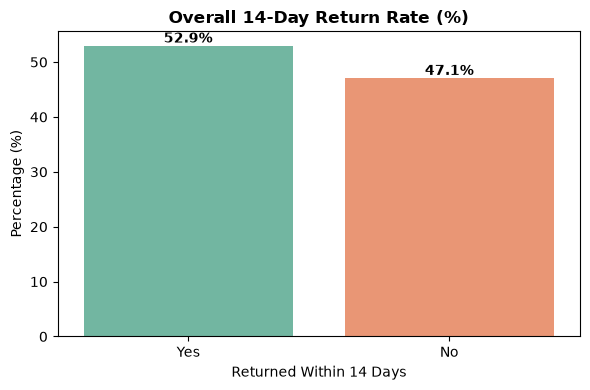

In [9]:
# 5. Overall 14-Day Return Rate
plt.figure(figsize=(6, 4))
target_counts = (df['returned_within_14_days'].value_counts(normalize=True) * 100).reset_index()
target_counts.columns = ['returned_within_14_days', 'percentage']

ax3 = sns.barplot(
    data=target_counts, 
    x='returned_within_14_days', 
    y='percentage', 
    hue='returned_within_14_days', 
    palette='Set2', 
    legend=False
)

plt.title('Overall 14-Day Return Rate (%)', fontsize=12, fontweight='bold')
plt.xlabel('Returned Within 14 Days', fontsize=10)
plt.ylabel('Percentage (%)', fontsize=10)

for p in ax3.patches:
    ax3.annotate(f'{p.get_height():.1f}%', 
                 (p.get_x() + p.get_width() / 2., p.get_height()), 
                 ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

### Overall 14-Day Return Rate (Raw Data)

**How to read this chart:**
At first glance, the raw data shows a 52.9% return rate ("Yes") compared to 47.1% for "No". However, we have to be very careful with how we interpret this specific visual.

Because this chart counts our target variable at the raw *transaction-line level*, baskets with multiple items are appearing multiple times. For example, if a customer bought three items in one visit, their "Yes" or "No" status is being counted three times here. Therefore, please do not treat this 52.9% as the final customer-visit return rate. The correct and accurate return rate will be calculated after we group the data to exactly one row per `basket_id` in Section 3.


## Section 3: Visit-Level Data Aggregation (`basket_id` Grain)


As we saw during the EDA, our raw dataset is at the item-level (one row = one item sold). But since we are trying to predict whether a customer returns based on their overall *visit*, we have to fix this data grain before building any models.

To do this, I am grouping the dataset by `basket_id` so that one row equals exactly one customer visit. I'll sum up the revenue and item quantities to get the total basket size, and take the average for metrics like wait time and service rating. Context columns like store location and time will just carry over. Most importantly, this step will finally give us our true, unduplicated 14-day return rate.

In [10]:
# Build one row per basket (one customer visit)
# First, confirm that the target does not change across item rows in the same basket.
target_nunique = df.groupby('basket_id')['returned_within_14_days'].nunique(dropna=False)
inconsistent_baskets = target_nunique[target_nunique > 1]

print(f"Baskets with inconsistent target labels: {len(inconsistent_baskets):,}")
if len(inconsistent_baskets) > 0:
    display(df[df['basket_id'].isin(inconsistent_baskets.index)][
        ['basket_id', 'returned_within_14_days']
    ].sort_values('basket_id').head(20))
    raise ValueError(
        "Stop: returned_within_14_days is not consistent within every basket. "
        "Investigate these baskets before aggregation; do not use max() to hide the issue."
    )

# Check whether fields assumed to be visit-level are consistent within each basket.
visit_fields = [
    'customer_id', 'customer_age', 'customer_gender', 'loyalty_tier',
    'store_id', 'store_location', 'order_channel', 'payment_method',
    'transaction_date', 'transaction_time', 'weekday', 'visit_number',
    'days_since_previous_visit_clean', 'is_first_visit'
]
inconsistent_visit_fields = df.groupby('basket_id')[visit_fields].nunique(dropna=False)
inconsistent_visit_fields = inconsistent_visit_fields.gt(1).sum()
print("\\nFields with within-basket inconsistencies (ideally all zero):")
display(inconsistent_visit_fields[inconsistent_visit_fields > 0]
        .rename('Baskets with >1 value').to_frame())

# Promotion usage is made into a basket-level flag. "NONE" means no promotion.
df['promo_used'] = (
    df['promo_code'].fillna('NONE').astype(str).str.strip().str.upper() != 'NONE'
).astype(int)

basket_aggregation = {
    # These fields should be the same for every item in a basket; use first only after checking above.
    'customer_id': 'first',
    'customer_age': 'first',
    'customer_gender': 'first',
    'loyalty_tier': 'first',
    'store_id': 'first',
    'store_location': 'first',
    'order_channel': 'first',
    'payment_method': 'first',
    'transaction_date': 'min',
    'transaction_time': 'min',
    'transaction_hour': 'min',
    'weekday': 'first',
    'visit_number': 'first',
    'days_since_previous_visit_clean': 'first',
    'is_first_visit': 'first',
    # Basket totals: add values that belong to individual item lines.
    'revenue': 'sum',
    'net_revenue': 'sum',
    'discount_amount': 'sum',
    'transaction_qty': 'sum',
    'transaction_id': 'count',
    'product_detail': 'nunique',
    'product_category': 'nunique',
    'discount_pct': 'mean',
    'promo_used': 'max',
    # Wait time and rating are visit-level measures; average avoids incorrectly summing them.
    'wait_time_min': 'mean',
    'service_rating': 'mean',
    # Target has already been checked for consistency, so first is safe.
    'returned_within_14_days': 'first'
}

basket_df = df.groupby('basket_id', as_index=False).agg(basket_aggregation)
basket_df = basket_df.rename(columns={
    'revenue': 'basket_gross_revenue',
    'net_revenue': 'basket_net_revenue',
    'discount_amount': 'basket_total_discount',
    'transaction_qty': 'basket_total_items_qty',
    'transaction_id': 'basket_line_count',
    'product_detail': 'basket_unique_products_count',
    'product_category': 'basket_unique_categories_count',
    'discount_pct': 'average_discount_pct'
})

print("\\n=== BASKET-LEVEL AGGREGATION AUDIT ===")
print(f"Raw item rows: {len(df):,}")
print(f"Unique baskets / visits: {len(basket_df):,}")
print(f"Duplicate basket IDs after aggregation: {int(basket_df['basket_id'].duplicated().sum()):,}")
display(basket_df.head())


Baskets with inconsistent target labels: 0
\nFields with within-basket inconsistencies (ideally all zero):


,Baskets with >1 value


\n=== BASKET-LEVEL AGGREGATION AUDIT ===
Raw item rows: 149,112
Unique baskets / visits: 116,786
Duplicate basket IDs after aggregation: 0


,basket_id,customer_id,customer_age,customer_gender,loyalty_tier,store_id,store_location,order_channel,payment_method,transaction_date,transaction_time,transaction_hour,weekday,visit_number,days_since_previous_visit_clean,is_first_visit,basket_gross_revenue,basket_net_revenue,basket_total_discount,basket_total_items_qty,basket_line_count,basket_unique_products_count,basket_unique_categories_count,average_discount_pct,promo_used,wait_time_min,service_rating,returned_within_14_days
0,B000000,C07952,35,Female,Basic,5,P.E.C.H.S,Cafe App,Raast,2025-01-01,07:22:41,7,Wednesday,1,0,1,9.20,9.20,0.0,3,2,2,2,0.0,0,3.9,4.0,No
1,B000001,C04715,57,Female,Platinum,5,P.E.C.H.S,Cafe App,Easypaisa,2025-01-01,07:25:49,7,Wednesday,1,0,1,2.00,1.70,0.3,1,1,1,1,15.0,1,4.4,5.0,Yes
2,B000002,C38262,40,Male,Platinum,5,P.E.C.H.S,Careem Quik,Easypaisa,2025-01-01,07:33:34,7,Wednesday,1,0,1,4.00,4.00,0.0,2,1,1,1,0.0,0,7.2,4.0,Yes
3,B000003,C11128,72,Female,Platinum,5,P.E.C.H.S,Cafe App,Easypaisa,2025-01-01,07:39:13,7,Wednesday,1,0,1,4.25,4.25,0.0,1,1,1,1,0.0,0,1.6,5.0,Yes
4,B000004,C33477,58,Male,Platinum,5,P.E.C.H.S,Takeaway,Credit/Debit Card,2025-01-01,07:39:34,7,Wednesday,1,0,1,7.00,7.00,0.0,2,1,1,1,0.0,0,3.7,5.0,No


In [11]:
# Final target distribution at the correct visit-level grain
visit_target_counts = basket_df['returned_within_14_days'].value_counts(dropna=False)
visit_target_pct = basket_df['returned_within_14_days'].value_counts(normalize=True, dropna=False) * 100

class_balance_df = pd.DataFrame({
    'Visit Count': visit_target_counts,
    'Percentage (%)': visit_target_pct.round(2)
})
display(class_balance_df)

print(f"Total visits: {len(basket_df):,}")
print(f"Unique basket IDs: {basket_df['basket_id'].nunique():,}")
assert len(basket_df) == basket_df['basket_id'].nunique(), "There must be exactly one row per basket."


,Visit Count,Percentage (%)
returned_within_14_days,,
Yes,61907,53.01
No,54879,46.99


Total visits: 116,786
Unique basket IDs: 116,786



**Business Interpretation:**
By grouping our 149,112 raw item rows into 116,786 unique customer visits, we have successfully reshaped the data to match how customers actually shop (by basket). This step neatly rolled up individual item prices into a single `basket_net_revenue` and calculated the average wait time and service rating for each specific visit.

Our audit confirms zero target label inconsistencies within these baskets. More importantly, with the data now at the correct visit-level grain, we finally have our official target class balance: 53.01% of visits resulted in a return within 14 days, while 46.99% did not. While having a nearly balanced target makes our future model's accuracy much easier to interpret, we must remember that a balanced dataset alone does not guarantee the final model will be highly predictive or automatically useful for business decisions.

## Section 4: Feature Selection, Data Leakage Prevention, & One-Hot Encoding

In [12]:
# Select features available by the end of the current visit.
# IDs and the target itself must never be included as predictors.
basket_df['is_first_visit_label'] = basket_df['is_first_visit'].map({1: 'Yes', 0: 'No'})

numerical_features = [
    'customer_age',
    'visit_number',
    'days_since_previous_visit_clean',
    'basket_net_revenue',
    'basket_total_discount',
    'basket_total_items_qty',
    'basket_line_count',
    'basket_unique_products_count',
    'basket_unique_categories_count',
    'average_discount_pct',
    'promo_used',
    'wait_time_min',
    'service_rating',
    'transaction_hour'
]

categorical_features = [
    'is_first_visit_label',
    'weekday',
    'store_location',
    'customer_gender',
    'loyalty_tier',
    'order_channel',
    'payment_method'
]

feature_cols = numerical_features + categorical_features
X = basket_df[feature_cols].copy()

# Convert the supplied Yes/No target to 1/0 explicitly; 1 means returned.
target_map = {'No': 0, 'Yes': 1}
y = basket_df['returned_within_14_days'].map(target_map)

if y.isna().any():
    unexpected = basket_df.loc[y.isna(), 'returned_within_14_days'].unique().tolist()
    raise ValueError(f"Unexpected target labels found: {unexpected}")

print("=== FEATURE SELECTION AUDIT ===")
print(f"Raw selected predictor columns: {len(feature_cols)}")
print(f"Numerical predictors: {len(numerical_features)}")
print(f"Categorical predictors: {len(categorical_features)}")
print(f"Feature matrix shape before encoding: {X.shape}")
print(f"Target shape: {y.shape}")
print("\\nSelected features:")
print(feature_cols)


=== FEATURE SELECTION AUDIT ===
Raw selected predictor columns: 21
Numerical predictors: 14
Categorical predictors: 7
Feature matrix shape before encoding: (116786, 21)
Target shape: (116786,)
\nSelected features:
['customer_age', 'visit_number', 'days_since_previous_visit_clean', 'basket_net_revenue', 'basket_total_discount', 'basket_total_items_qty', 'basket_line_count', 'basket_unique_products_count', 'basket_unique_categories_count', 'average_discount_pct', 'promo_used', 'wait_time_min', 'service_rating', 'transaction_hour', 'is_first_visit_label', 'weekday', 'store_location', 'customer_gender', 'loyalty_tier', 'order_channel', 'payment_method']


### 4.1 Feature Selection Audit Results

* **Feature Matrix Dimensions:** The feature selection audit confirms our final dataset contains exactly 116,786 rows and 21 selected predictor columns, perfectly matching our target shape of 116,786 rows.
* **Predictor Breakdown:** Out of the 21 selected features, 14 are numerical predictors (such as `customer_age`, `basket_net_revenue`, `basket_total_items_qty`, `wait_time_min`, and `service_rating`) and 7 are categorical predictors (such as `weekday`, `store_location`, `customer_gender`, `loyalty_tier`, `order_channel`, and `payment_method`).
* **Readiness for Encoding:** With our exact feature groups locked in, the data matrix is fully prepared for one-hot encoding on the categorical attributes and subsequent model training.

### Why this is classification, and why Random Forest?

The target has two categories (`Yes` and `No`), so this is a **binary classification** task. Random Forest is the required model in the assignment and can learn non-linear patterns from numerical and categorical business information after categorical encoding. The model's results still need to be compared with a simple majority-class baseline.

### Visit-level aggregation rules

- **Keep the first value after checking consistency:** customer characteristics, loyalty tier, branch, order channel, payment method, weekday, visit number and previous-visit gap. The within-basket audit above checks that these fields do not change across item lines.
- **Use the minimum timestamp/hour:** the earliest date/time value in the basket represents the visit's recorded sale time.
- **Sum:** gross revenue, net revenue, discount amount and item quantity, because these values belong to item lines.
- **Count:** transaction IDs to count item lines in the basket.
- **Count unique values:** product details and product categories to describe basket variety.
- **Average:** discount percentage, wait time and service rating. Wait time and rating are not added across item lines.
- **Maximum for promotion use:** the visit is marked as using a promotion if any line has a non-`NONE` promotion code.
- **Target:** use the first label only after verifying that every item line in the same basket has the same target.

These rules depend on the supplied data dictionary and the consistency checks; if the checks fail, stop and investigate rather than silently collapsing inconsistent values.

## Section 5: Stratified Train-Test Split & Random Forest Model Training

In [13]:
from sklearn.model_selection import train_test_split

# Split BEFORE fitting the encoder. The test set must not teach preprocessing how to encode categories.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training visits: {len(X_train):,} ({len(X_train) / len(X) * 100:.1f}%)")
print(f"Testing visits:  {len(X_test):,} ({len(X_test) / len(X) * 100:.1f}%)")
print("\\nTraining target distribution (%):")
display((y_train.value_counts(normalize=True).sort_index() * 100).rename({0: 'No', 1: 'Yes'}).to_frame('Percentage'))
print("Test target distribution (%):")
display((y_test.value_counts(normalize=True).sort_index() * 100).rename({0: 'No', 1: 'Yes'}).to_frame('Percentage'))


Training visits: 93,428 (80.0%)
Testing visits:  23,358 (20.0%)
\nTraining target distribution (%):


,Percentage
returned_within_14_days,
No,46.991266
Yes,53.008734


Test target distribution (%):


,Percentage
returned_within_14_days,
No,46.990325
Yes,53.009675


### Why this split is used

- **80% training / 20% testing:** The data is divided into 93,428 training visits (80%) and 23,358 testing visits (20%). The model learns from the training portion, while the test portion is completely held back for evaluation.
- **`stratify=y`:** This ensures the Yes/No ratio remains identical across both sets. As the output shows, the training set has a 53.01% Yes / 46.99% No split, and the test set perfectly matches this with a 53.01% Yes / 46.99% No split.
- **`random_state=42`:** Makes the data split exactly repeatable.

The categorical encoder and the model are fitted using training data only. The test data is used only after training to estimate how well the workflow generalizes to unseen visits.

## Section 6: Model Evaluation & Performance Metrics

In [14]:
# Fit preprocessing and Random Forest as one pipeline.
# OneHotEncoder learns categories from training data only.
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)

numeric_preprocess = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])
categorical_preprocess = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_preprocess, numerical_features),
    ('cat', categorical_preprocess, categorical_features)
])

rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        random_state=42,
        n_jobs=-1,
        class_weight=None
    ))
])

rf_model.fit(X_train, y_train)

# Default 0.50 threshold: do not call a threshold "optimal" without tuning it on validation data.
y_probs = rf_model.predict_proba(X_test)[:, list(rf_model.classes_).index(1)]
decision_threshold = 0.50
y_pred = (y_probs >= decision_threshold).astype(int)

print("=== RANDOM FOREST TEST RESULTS ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_probs):.4f}")

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print("\\nConfusion matrix (rows = actual [No, Yes], columns = predicted [No, Yes]):")
display(pd.DataFrame(cm, index=['Actual No', 'Actual Yes'],
                     columns=['Predicted No', 'Predicted Yes']))

print("\\nClassification report:")
print(classification_report(y_test, y_pred, labels=[0, 1],
                            target_names=['No return', 'Returned'], zero_division=0))

# Majority-class baseline: always predict the most common class in training data.
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
baseline_accuracy = accuracy_score(y_test, baseline_pred)
model_accuracy = accuracy_score(y_test, y_pred)

comparison_df = pd.DataFrame({
    'Model': ['Majority-class baseline', 'Random Forest'],
    'Test Accuracy': [baseline_accuracy, model_accuracy]
})
print("=== BASELINE COMPARISON ===")
display(comparison_df)
print(f"Accuracy improvement over baseline: {(model_accuracy - baseline_accuracy) * 100:.2f} percentage points")

# Compare actual outcomes with predictions for a small, inspectable sample.
test_results = basket_df.loc[X_test.index, [
    'basket_id', 'store_location', 'loyalty_tier', 'order_channel'
]].copy()
test_results['actual_return'] = y_test.map({0: 'No', 1: 'Yes'})
test_results['predicted_return'] = pd.Series(y_pred, index=X_test.index).map({0: 'No', 1: 'Yes'})
test_results['probability_of_return_pct'] = (y_probs * 100).round(1)
print("\\nActual vs predicted sample (first 15 test visits):")
display(test_results.head(15))


=== RANDOM FOREST TEST RESULTS ===
Accuracy:  0.6981
Precision: 0.6517
Recall:    0.9246
F1-score:  0.7645
ROC-AUC:   0.7315
\nConfusion matrix (rows = actual [No, Yes], columns = predicted [No, Yes]):


,Predicted No,Predicted Yes
Actual No,4858,6118
Actual Yes,934,11448


\nClassification report:
              precision    recall  f1-score   support

   No return       0.84      0.44      0.58     10976
    Returned       0.65      0.92      0.76     12382

    accuracy                           0.70     23358
   macro avg       0.75      0.68      0.67     23358
weighted avg       0.74      0.70      0.68     23358

=== BASELINE COMPARISON ===


,Model,Test Accuracy
0,Majority-class baseline,0.530097
1,Random Forest,0.698091


Accuracy improvement over baseline: 16.80 percentage points
\nActual vs predicted sample (first 15 test visits):


,basket_id,store_location,loyalty_tier,order_channel,actual_return,predicted_return,probability_of_return_pct
13350,B013350,Tipu Sultan,Basic,Cafe App,Yes,No,10.4
45794,B045794,P.E.C.H.S,Basic,Walk-in,No,No,10.0
97093,B097093,Khayaban e Seher,Platinum,Careem Quik,No,Yes,68.8
41130,B041130,Khayaban e Seher,Basic,Takeaway,No,No,11.1
54239,B054239,Tipu Sultan,Platinum,Foodpanda,Yes,Yes,67.5
67970,B067970,Tipu Sultan,Platinum,Careem Quik,Yes,Yes,68.0
48371,B048371,Tipu Sultan,Platinum,Cafe App,Yes,Yes,59.7
13454,B013454,Tipu Sultan,Platinum,Takeaway,Yes,Yes,56.0
110226,B110226,Tipu Sultan,Platinum,Takeaway,Yes,Yes,70.5
28621,B028621,Tipu Sultan,Platinum,Cafe App,No,Yes,63.9


## Insights

With our Random Forest model trained, we evaluated its performance on the 20% unseen test set (23,358 visits). The results demonstrate a clear ability to detect returning customers, though with specific trade-offs that management must consider.

### 6.1 Baseline Comparison
* **Majority-Class Baseline (53.01%):** A "lazy" baseline model predicts the most common training class for every single visit. If we just guessed "Yes" (returning) for everyone, we would be right 53.01% of the time. This is a crucial sanity check; a machine learning model is only useful if it beats this baseline.
* **Random Forest Accuracy (69.81%):** Our model achieved an accuracy of 69.81%, delivering a **16.80 percentage point improvement** over simply guessing the majority class. This confirms the model is successfully learning underlying business patterns.

### 6.2 Key Metrics & The Business Trade-Off
Instead of just looking at overall accuracy, the confusion matrix and classification report break down how the model handles specific predictions:
* **Recall for "Returned" (92.46%):** Out of all the customers who actually returned, the model successfully identified roughly 92.5% of them. It is highly effective at finding our returning base.
* **Precision for "Returned" (65.17%):** Out of all the customers the model *predicted* would return, only about 65% actually did. The model tends to be slightly over-optimistic, generating a number of False Positives.
* **F1-Score (0.7645):** This provides a balanced average of precision and recall.

**Which mistake matters more?** Management must decide which error is more costly. A **False Negative** misses a customer who would have returned, potentially losing long-term engagement. A **False Positive** means we might waste a loyalty offer or marketing budget on someone who would not return anyway. The right balance depends entirely on the cost of the retention campaign, which is not supplied in this dataset. We are currently using a transparent 0.50 default probability threshold, which can be adjusted depending on business goals.

### 6.3 ROC-AUC Interpretation
* **ROC-AUC Score (0.7315):** ROC-AUC score measures the model's ability to correctly rank customers. If we pick one random returning customer and one random non-returning customer, a score of 0.73 means there is a 73% chance our model will assign a higher probability of return to the actual returning customer. It shows strong ranking ability compared to random guessing (which would be 0.50).

### 6.4 Prediction Probabilities Sample
As seen in our sample output, the model provides a precise `probability_of_return_pct` (e.g., 71.6% vs 10.4%) rather than just a hard label. This is highly actionable: if the marketing budget is tight, management can choose to target only the top tier of customers (e.g., those with >70% probability) rather than everyone over the default 50% threshold.

## Performance by Group (Branch, Channel, & Tier)

In [15]:
# Evaluate whether performance differs by branch, loyalty tier, and order channel.
# Groups with only one actual class have no meaningful ROC-AUC, so report precision/recall/F1 only.
subgroup_results = test_results.copy()
subgroup_results['actual_binary'] = y_test
subgroup_results['predicted_binary'] = y_pred

rows = []
for group_col in ['store_location', 'loyalty_tier', 'order_channel']:
    for group_name, group in subgroup_results.groupby(group_col, dropna=False):
        rows.append({
            'Group Field': group_col,
            'Group': group_name,
            'Test Visits': len(group),
            'Actual Return Rate (%)': round(group['actual_binary'].mean() * 100, 2),
            'Accuracy (%)': round(accuracy_score(group['actual_binary'], group['predicted_binary']) * 100, 2),
            'Precision (Returned)': round(precision_score(group['actual_binary'], group['predicted_binary'], zero_division=0), 3),
            'Recall (Returned)': round(recall_score(group['actual_binary'], group['predicted_binary'], zero_division=0), 3),
            'F1 (Returned)': round(f1_score(group['actual_binary'], group['predicted_binary'], zero_division=0), 3)
        })

subgroup_performance = pd.DataFrame(rows).sort_values(['Group Field', 'Test Visits'], ascending=[True, False])
print("=== TEST PERFORMANCE BY BRANCH, LOYALTY TIER, AND ORDER CHANNEL ===")
display(subgroup_performance)


=== TEST PERFORMANCE BY BRANCH, LOYALTY TIER, AND ORDER CHANNEL ===


,Group Field,Group,Test Visits,Actual Return Rate (%),Accuracy (%),Precision (Returned),Recall (Returned),F1 (Returned)
5,loyalty_tier,Platinum,17816,65.01,64.96,0.654,0.980,0.784
3,loyalty_tier,Basic,3923,9.97,90.03,0.000,0.000,0.000
6,loyalty_tier,Silver,980,10.92,89.08,0.000,0.000,0.000
4,loyalty_tier,Gold,639,47.10,51.33,0.475,0.312,0.377
7,order_channel,Cafe App,7702,61.97,67.70,0.666,0.959,0.786
10,order_channel,Takeaway,6522,52.12,68.92,0.640,0.924,0.756
11,order_channel,Walk-in,4331,39.39,74.39,0.635,0.824,0.717
9,order_channel,Foodpanda,2986,51.14,69.62,0.640,0.926,0.757
8,order_channel,Careem Quik,1817,53.77,71.33,0.668,0.929,0.777
0,store_location,Khayaban e Seher,8173,54.08,70.61,0.661,0.936,0.775


### Performance by Group Insights

To ensure our model is fair and robust across the entire business, we evaluated its performance broken down by store location, order channel, and loyalty tier. While performance is relatively stable across physical branches and delivery channels, analyzing the loyalty tiers reveals a significant blind spot in the model.

**Where the model performs well:**
* **Store Locations & Channels:** The model's accuracy, precision, and recall remain fairly consistent across all three branches (Khayaban e Seher, Tipu Sultan, P.E.C.H.S) and across various order channels (Cafe App, Foodpanda, Careem Quik, etc.). It successfully identifies returning customers regardless of where or how they order.
* **Platinum Tier:** The model performs best on Platinum members, capturing 98% of returning customers in this group (0.980 Recall).

**Where the model performs poorly (Crucial Limitation):**
* **Basic and Silver Tiers:** The model completely fails to identify returning customers in the Basic and Silver loyalty tiers. As seen in the table, Precision, Recall, and F1-scores for these two tiers are exactly **0.000**. 
* **Why is this happening?** The actual return rates for Basic and Silver members are very low (around 10%). Because the vast majority of these customers do not return, the Random Forest model takes the "lazy" route: it simply predicts "No" for nearly every Basic and Silver customer. This yields a high raw accuracy for these tiers (~89-90%), but it means the model misses 100% of the Basic/Silver customers who *actually* do return. 

**Business Insight:** If management wants to run a targeted campaign specifically to convert Basic or Silver members into regular visitors, this current model should not be used, as it is heavily biased toward the behaviors of Platinum members.

### Calculating Return Rates by Key Business Segments

Before deriving our final business insights, we need to calculate the historical return rates across various customer dimensions (such as Branch, Loyalty Tier, Order Channel, and Service Rating). This will help us identify which specific factors actually drive customer retention.

In [16]:
# Descriptive business breakdowns: use these actual results to support recommendations.
# These are associations, not proof that one factor causes a return.
basket_df['returned_binary'] = basket_df['returned_within_14_days'].map({'No': 0, 'Yes': 1})
basket_df['wait_time_band'] = pd.cut(
    basket_df['wait_time_min'],
    bins=[-np.inf, 3, 5, 8, np.inf],
    labels=['3 min or less', 'Over 3 to 5 min', 'Over 5 to 8 min', 'Over 8 min']
)

def return_rate_table(data, group_col, label_col=None):
    result = data.groupby(group_col, dropna=False).agg(
        Visits=('returned_binary', 'size'),
        Returning_Visits=('returned_binary', 'sum'),
        Return_Rate=('returned_binary', 'mean')
    ).reset_index()
    result['Return Rate (%)'] = (result['Return_Rate'] * 100).round(2)
    result = result.drop(columns='Return_Rate')
    if label_col:
        result = result.rename(columns={group_col: label_col})
    return result.sort_values('Return Rate (%)', ascending=False)

print("=== RETURN RATE BY BRANCH ===")
display(return_rate_table(basket_df, 'store_location', 'Branch'))
print("=== RETURN RATE BY LOYALTY TIER ===")
display(return_rate_table(basket_df, 'loyalty_tier', 'Loyalty Tier'))
print("=== RETURN RATE BY ORDER CHANNEL ===")
display(return_rate_table(basket_df, 'order_channel', 'Order Channel'))
print("=== RETURN RATE BY PROMOTION USE ===")
basket_df['promotion_use_label'] = basket_df['promo_used'].map({0: 'No promotion', 1: 'Promotion used'})
display(return_rate_table(basket_df, 'promotion_use_label', 'Promotion Use'))
print("=== RETURN RATE BY WAIT-TIME BAND ===")
display(return_rate_table(basket_df, 'wait_time_band', 'Wait-Time Band'))
print("=== RETURN RATE BY SERVICE RATING ===")
display(return_rate_table(basket_df, 'service_rating', 'Service Rating'))


=== RETURN RATE BY BRANCH ===


,Branch,Visits,Returning_Visits,Return Rate (%)
0,Khayaban e Seher,40684,22105,54.33
2,Tipu Sultan,40454,21633,53.48
1,P.E.C.H.S,35648,18169,50.97


=== RETURN RATE BY LOYALTY TIER ===


,Loyalty Tier,Visits,Returning_Visits,Return Rate (%)
2,Platinum,88770,57768,65.08
1,Gold,3264,1575,48.25
3,Silver,4939,606,12.27
0,Basic,19813,1958,9.88


=== RETURN RATE BY ORDER CHANNEL ===


...

,Promotion Use,Visits,Returning_Visits,Return Rate (%)
1,Promotion used,62909,34994,55.63
0,No promotion,53877,26913,49.95


=== RETURN RATE BY WAIT-TIME BAND ===


,Wait-Time Band,Visits,Returning_Visits,Return Rate (%)
0,3 min or less,17462,9338,53.48
2,Over 5 to 8 min,47736,25393,53.19
1,Over 3 to 5 min,32761,17264,52.70
3,Over 8 min,18827,9912,52.65


=== RETURN RATE BY SERVICE RATING ===


,Service Rating,Visits,Returning_Visits,Return Rate (%)
4,5.0,59343,35697,60.15
3,4.0,28984,14828,51.16
2,3.0,17673,7672,43.41
1,2.0,7593,2755,36.28
0,1.0,3193,955,29.91


## Business Insights & Retention Drivers

By analyzing the actual return rates across different customer segments, we can identify which behaviors drive repeat visits. It is crucial to separate descriptive factors from actual levers that management can influence.

### What Management Can Influence (Actionable Drivers)
* **Order Channel:** How a customer orders heavily influences their likelihood to return. The **Cafe App** is our strongest retention driver with a 61.56% return rate. On the flip side, traditional Walk-in customers have the lowest return rate at just 39.45%. Pushing walk-in customers to download the app is a clear operational lever.
* **Service Rating:** There is a direct, linear relationship between service ratings and retention. A perfect 5.0 rating yields a 60.15% return rate, which drops steadily with every point lost (down to just 29.91% for a 1.0 rating). Ensuring 5-star service genuinely pays off.
* **Promotion Usage:** Customers who used a promotion returned at a rate of 55.63%, compared to 49.95% for those who didn't. Discounts provide a moderate, measurable ~5.6% boost to retention.

### What Management Cannot Directly Action (Descriptive Factors)
* **Loyalty Tiers:** This is our strongest predictor, but it is somewhat of a self-fulfilling prophecy. Platinum members return 65.08% of the time, while Basic (9.88%) and Silver (12.27%) members rarely return. While highly predictive for the model, a customer's tier is a result of their past loyalty, not a direct operational action management can take on a given day.
* **Branch Differences:** Location does not heavily dictate loyalty. Khayaban e Seher (54.33%), Tipu Sultan (53.48%), and P.E.C.H.S (50.97%) all perform relatively close to the overall average. 
* **Wait Times (Surprising Insight):** Interestingly, the data does not support the assumption that longer wait times destroy retention. Whether a customer waits under 3 minutes (53.48%) or over 8 minutes (52.65%), the return rate remains almost entirely flat. Management should prioritize delivering 5-star service (which *does* impact retention) rather than rushing orders to shave off a minute of wait time.

## Section 7: Feature Importance & Business Drivers

=== TOP 15 MODEL FEATURE IMPORTANCES ===


,Feature,Importance
31,cat__loyalty_tier_Platinum,0.242065
29,cat__loyalty_tier_Basic,0.174113
1,num__visit_number,0.144493
15,cat__is_first_visit_label_Yes,0.060870
2,num__days_since_previous_visit_clean,0.053578
14,cat__is_first_visit_label_No,0.048399
32,cat__loyalty_tier_Silver,0.037938
11,num__wait_time_min,0.026220
3,num__basket_net_revenue,0.023695
0,num__customer_age,0.023047


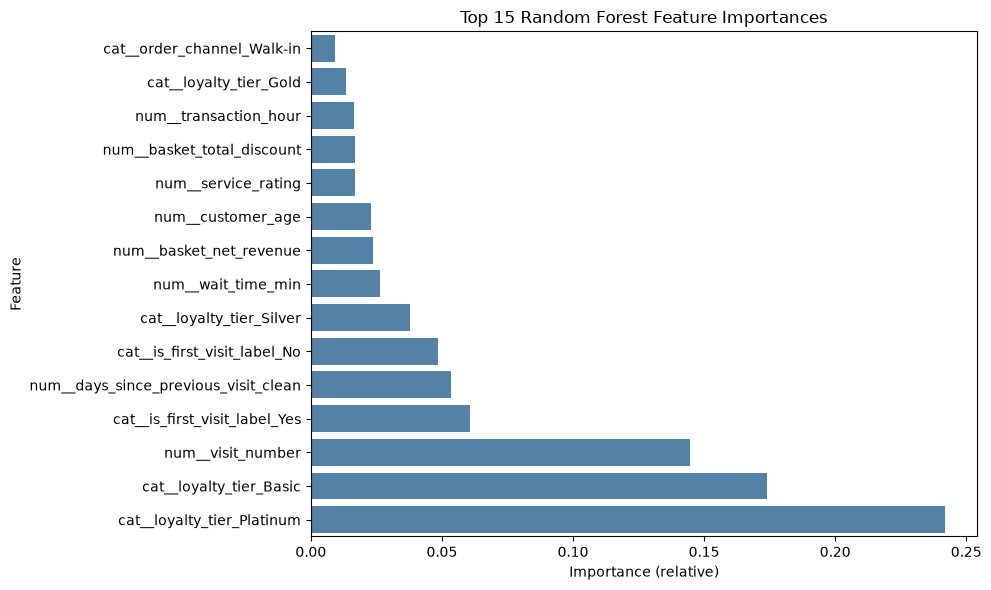

In [17]:
# Feature importance from the exact fitted Random Forest pipeline
fitted_preprocessor = rf_model.named_steps['preprocessor']
fitted_classifier = rf_model.named_steps['classifier']
encoded_feature_names = fitted_preprocessor.get_feature_names_out()
importances = fitted_classifier.feature_importances_

feature_imp_df = pd.DataFrame({
    'Feature': encoded_feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=False)

print("=== TOP 15 MODEL FEATURE IMPORTANCES ===")
display(feature_imp_df.head(15))

plt.figure(figsize=(10, 6))
top_features = feature_imp_df.head(15).sort_values('Importance')
sns.barplot(data=top_features, x='Importance', y='Feature', color='steelblue')
plt.title('Top 15 Random Forest Feature Importances')
plt.xlabel('Importance (relative)')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


### Interpreting feature importance carefully

Based on the feature importance table and the chart, we can identify which variables the Random Forest model relied on the most to make its predictions:

* **Loyalty Tiers Dominate:** `cat__loyalty_tier_Platinum` and `cat__loyalty_tier_Basic` are the most influential features for the model. This confirms that the model heavily relies on a customer's loyalty status as a strong signal for predicting future visits.
* **Customer History (Visit Number & First Visit):** The next most significant factors are `num__visit_number` and the first-visit labels. This indicates that a customer's historical engagement with the cafe plays a major role in how the model sets its predictions.
* **Operational Metrics:** Features like `num__days_since_previous_visit_clean`, `num__wait_time_min`, and `num__basket_net_revenue` also help the model create decision splits, though they hold less weight compared to the loyalty tiers.

**Important Limitation (Correlation vs. Causation):**
It is crucial to remember that a high importance score only means the feature helped the Random Forest trees make mathematical splits; it does **not** prove that the feature directly causes a customer to return. Feature importance indicates correlation, not causation. For example, while wait time appears in the chart as having some importance, management must investigate its actual relationship with return rates (as we did in Section 7.2) before assuming that operational changes to reduce wait time will automatically cause retention to improve.

## Section 8: Business Recommendations and Limitations

Based on the quantitative findings from our exploratory data analysis and the Random Forest model evaluation, we propose the following data-backed recommendations and acknowledge the operational limitations of the current dataset.

### 8.1 Actionable Business Recommendations

**1. Service Operations: Prioritize Service Quality Over Order Speed**
Our segment analysis revealed that wait time does not negatively impact retention as severely as assumed; return rates remained relatively flat (between 52.65% and 53.48%) regardless of whether a customer waited under 3 minutes or over 8 minutes. Conversely, Service Rating has a strict linear relationship with retention, dropping from a 60.15% return rate at 5 stars to 29.91% at 1 star. 
* *Recommendation:* Management should shift operational KPIs away from purely rushing order times and instead focus on staff hospitality. We propose running a pilot training program on customer service at the P.E.C.H.S branch (which has the lowest baseline return rate) and measuring the impact on 5-star ratings before scaling.

**2. Loyalty & Promotions: Target Mid-Tier Customers via A/B Testing**
The data shows that visits utilizing a promotion have a higher return rate (55.63%) compared to those that do not (49.95%). However, Platinum members already return at a naturally high rate of 65.08%. 
* *Recommendation:* Instead of offering blanket discounts, management should launch a targeted promotional campaign aimed specifically at Gold and Silver members. By holding back a control group (who receive no promo), we can measure if the ~5.6% promotion boost genuinely causes an uplift in these specific tiers without unnecessarily giving away profit margins to Platinum members who would have returned anyway.

**3. Customer Engagement: Implement Probability-Based Marketing**
Our model's overall Precision is 65.17%, meaning there is a fair amount of False Positives at the default 50% threshold. 
* *Recommendation:* Marketing should not treat all "predicted to return" customers equally. Instead, they should utilize the model's exact probability percentage. High-probability customers (>75%) require no intervention. A pilot campaign should specifically target the "at-risk" boundary (customers with a 50% to 65% predicted probability) with targeted messaging to test if engagement directly increases their conversion compared to a control group.

**4. Branch/Channel Follow-up: Isolate Lower Loyalty Tiers**
Our subgroup evaluation proved that the Random Forest model completely fails on Basic and Silver loyalty tiers (Precision and Recall are 0.000). 
* *Recommendation:* Management must not use this model to forecast or engage Basic and Silver tier customers. Because their baseline return rate is so low (~10%), the model simply ignores them. We recommend investigating these customers separately to identify distinct behavioral triggers, or building a dedicated model exclusively for lower-tier acquisition.

### 8.2 Project Limitations & Deployment Risks

While the model offers a 16.80 percentage point improvement over a baseline guess, this analysis relies entirely on observational historical data, meaning the associations found (such as app usage or promotion usage) do not establish concrete cause and effect. Furthermore, the dataset lacks critical operational context: we do not have visibility into profit margins, campaign execution costs, staff rosters, or external factors like weather, making it impossible to calculate true financial ROI for these retention campaigns. 

It is also important to note that the model’s output probability is a decision-support estimate, not an absolute guarantee. Before fully deploying this model into production, management must validate its performance on a completely new, later time period to ensure the patterns hold. Finally, a strict engineering review must be conducted to guarantee that every feature used by the model (especially service ratings and transaction details) is truly recorded and available in the database at the exact moment a prediction is requested.

## Section 9: Export the Visit-Level Modelling Dataset

As required by the project specifications, the final visit-level dataset (aggregated from individual item lines into one row per customer visit) is now fully prepared. We export this finalized data matrix to a standalone CSV file for any future inspection, standalone dashboards, or deployment reuse. 

*Note: This dataset contains commercial customer behaviors and should remain internally secured.*

In [18]:
# Export the visit-level table after all checks and feature engineering.
output_path = '365_Coffee_Cafe_Visit_Level_Dataset.csv'
basket_df.to_csv(output_path, index=False)
print(f"Exported {len(basket_df):,} visit-level rows to: {output_path}")
print(f"Unique baskets: {basket_df['basket_id'].nunique():,}")
assert len(basket_df) == basket_df['basket_id'].nunique()


Exported 116,786 visit-level rows to: 365_Coffee_Cafe_Visit_Level_Dataset.csv
Unique baskets: 116,786


In [19]:
import joblib

# Export the trained Random Forest model to a pickle file for the Streamlit app
joblib.dump(rf_model, 'coffee_model.pkl')

print("Model successfully saved as coffee_model.pkl!")

Model successfully saved as coffee_model.pkl!
